# Proof Of Concept : Bacterial phase classification

## Setup

### Imports

In [9]:
import os

import torch
import torch.nn as nn
from torchvision import transforms
from torchvision import datasets
from torch.utils.data import DataLoader, random_split

from tqdm.notebook import tqdm
import random
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import shutil
import random

### Setup GPU

In [10]:
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Device:", device)

Device: mps


## Utility methods

In [11]:
def count_images_dataset(class_folders):
  res = {}
  for class_name, folder_path in class_folders.items():
    if not os.path.isdir(folder_path):
        print(f"Error: Folder '{folder_path}' for class '{class_name}' not found.")
        continue

    image_count = 0

    for root, _, files in os.walk(folder_path):
        for file_name in files:
            # Assuming image files have common extensions, adjust if needed
            if file_name.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp', '.tiff')):
                file_path = os.path.join(root, file_name)
                image_count += 1

    res[class_name] = image_count

  return res

In [12]:
def display_samples(class_folders, n_samples):
  plt.figure(figsize=(12, 4))

  for i, (class_name, folder) in enumerate(class_folders.items()):
    # List all images in the folder
    images = os.listdir(folder)

    # Randomly select 3 images
    samples = random.sample(images, n_samples)

    for j, img_name in enumerate(samples):
      img_path = os.path.join(folder, img_name)

      # Read image with OpenCV (BGR)
      img = cv2.imread(img_path)
      img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)  # convert to grayscale for display

      plt.subplot(len(class_folders), n_samples, i * n_samples + j + 1)
      plt.imshow(img, cmap='gray')
      plt.title(f"{class_name}")

## Dataset

### Loading the dataset


- The dataset can be downloaded from this [Google Drive link](https://drive.google.com/file/d/1SnEeprczqss7kedEh235iMHJKjpcSNY6/view?usp=drive_link).

- <ins>Add the archive to your own Google Drive</ins> (the method used in this notebook) or <ins>just extract it manually.</ins>

#### Option 1 - Load from Google Drive

In [13]:
# Mount the Google Drive containing the dataset
drive.mount('/content/drive')

# Unzip the dataset from drive in "/content/dataset" folder
!unzip -q "/content/drive/MyDrive/bacteria_dataset.zip" -d "/content/dataset"

NameError: name 'drive' is not defined

#### Option 2 - Load the dataset manually

If the `dataset.zip` archive was manually imported into Colab.

In [ ]:
# Unzip the dataset from Colab files in "/content/dataset" folder
!unzip -q "/content/dataset.zip" -d "/content/dataset"

unzip:  cannot find or open /content/dataset.zip, /content/dataset.zip.zip or /content/dataset.zip.ZIP.


### Exploring the dataset

The dataset contains images of the Sporosarcina pasteurii bacteria taken using a microscope. The images are divided in two classes which represent two phase of the bacterial development: exposition and post exposition.

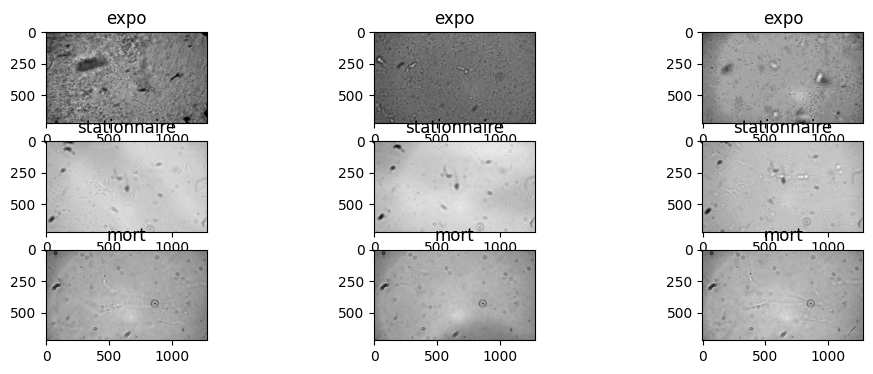

In [ ]:
class_folders = {
    "expo": "dataset/expo",
    "stationnaire": "dataset/stationnaire",
    "mort": "dataset/mort"
}

display_samples(class_folders, 3)

expo: 10200 images
stationnaire: 1242 images
mort: 293 images


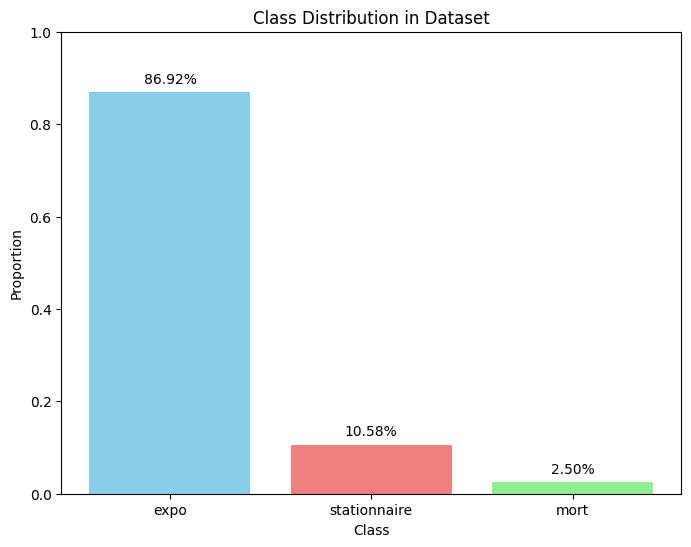

In [ ]:
image_counts = count_images_dataset(class_folders)
for class_name, count in image_counts.items():
  print(f"{class_name}: {count} images")

total_images = sum(image_counts.values())

class_names = list(image_counts.keys())
proportions = [count / total_images for count in image_counts.values()]

plt.figure(figsize=(8, 6))
plt.bar(class_names, proportions, color=['skyblue', 'lightcoral', 'lightgreen'])
plt.xlabel('Class')
plt.ylabel('Proportion')
plt.title('Class Distribution in Dataset')
plt.ylim(0, 1)

for i, proportion in enumerate(proportions):
    plt.text(i, proportion + 0.02, f'{proportion:.2%}', ha='center')

plt.show()

## Preprocessing the dataset

In [ ]:
dataset_dir = "dataset"
train_dir = "train"
test_dir = "test"
split_ratio = 0.8
seed = 42

random.seed(seed)

# Create train/test dirs
for split_dir in [train_dir, test_dir]:
    os.makedirs(split_dir, exist_ok=True)

# Loop over each class
for class_name in os.listdir(dataset_dir):
    class_path = os.path.join(dataset_dir, class_name)
    if not os.path.isdir(class_path):
        continue

    images = os.listdir(class_path)
    random.shuffle(images)

    split_idx = int(len(images) * split_ratio)
    train_images = images[:split_idx]
    test_images = images[split_idx:]

    # Create class folders
    os.makedirs(os.path.join(train_dir, class_name), exist_ok=True)
    os.makedirs(os.path.join(test_dir, class_name), exist_ok=True)

    # Copy files
    for img in train_images:
        shutil.copy(
            os.path.join(class_path, img),
            os.path.join(train_dir, class_name, img)
        )

    for img in test_images:
        shutil.copy(
            os.path.join(class_path, img),
            os.path.join(test_dir, class_name, img)
        )

    print(f"{class_name}: {len(train_images)} train / {len(test_images)} test")

mort: 234 train / 59 test
stationnaire: 993 train / 249 test
expo: 8160 train / 2040 test


In [ ]:
def flip_images(path=None, horizontal_flip=True, vertical_flip=True, probability=1):
  if not path or not os.path.isdir(path):
    print(f"Error: Invalid path '{path}' provided.")
    return

  images = [f for f in os.listdir(path) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp', '.tiff'))]

  for img_name in images:
    img_path = os.path.join(path, img_name)
    try:
      img = Image.open(img_path)
      base_name, ext = os.path.splitext(img_name)

      # Apply horizontal flip
      if horizontal_flip and random.random() < probability:
        h_flipped_img = img.transpose(Image.FLIP_LEFT_RIGHT)
        h_flipped_img_name = f"{base_name}_hflip{ext}"
        h_flipped_img.save(os.path.join(path, h_flipped_img_name))

      # Apply vertical flip
      if vertical_flip and random.random() < probability:
        v_flipped_img = img.transpose(Image.FLIP_TOP_BOTTOM)
        v_flipped_img_name = f"{base_name}_vflip{ext}"
        v_flipped_img.save(os.path.join(path, v_flipped_img_name))

    except Exception as e:
      print(f"Could not process image {img_name}: {e}")

In [ ]:
flip_images("train/mort", True, True, 1)

In [ ]:
flip_images("train/stationnaire", True, True, 0.5)

expo: 8160 images
stationnaire: 2018 images
mort: 702 images


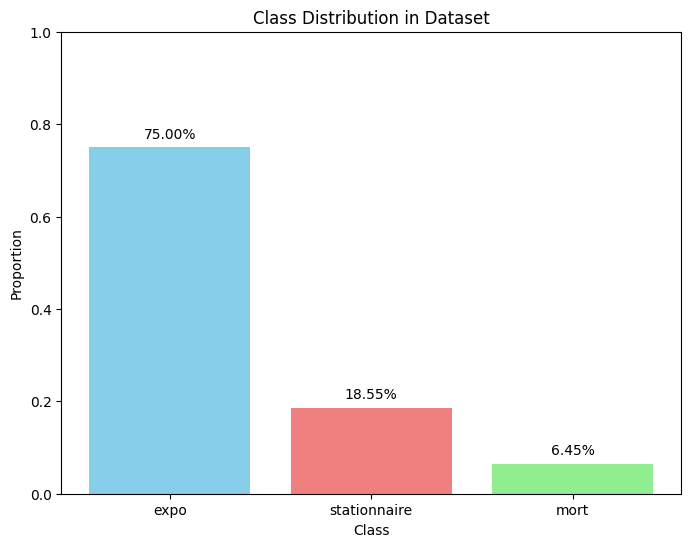

In [ ]:
train_folders = {
    "expo": "train/expo",
    "stationnaire": "train/stationnaire",
    "mort": "train/mort"
}

image_counts = count_images_dataset(train_folders)
for class_name, count in image_counts.items():
  print(f"{class_name}: {count} images")

total_images = sum(image_counts.values())

class_names = list(image_counts.keys())
proportions = [count / total_images for count in image_counts.values()]

plt.figure(figsize=(8, 6))
plt.bar(class_names, proportions, color=['skyblue', 'lightcoral', 'lightgreen'])
plt.xlabel('Class')
plt.ylabel('Proportion')
plt.title('Class Distribution in Dataset')
plt.ylim(0, 1)

for i, proportion in enumerate(proportions):
    plt.text(i, proportion + 0.02, f'{proportion:.2%}', ha='center')

plt.show()

## Training the CNN

In [ ]:
from torchvision import datasets, transforms

temp_transform = transforms.Compose([
    transforms.Grayscale(1),
    transforms.ToTensor()
])

temp_dataset = datasets.ImageFolder(
    "dataset",
    transform=temp_transform
)

In [ ]:
from torch.utils.data import random_split

train_size = int(0.8 * len(temp_dataset))
val_size = len(temp_dataset) - train_size

train_ds, _ = random_split(
    temp_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

In [ ]:
import torch
from torch.utils.data import DataLoader

loader = DataLoader(
    train_ds,
    batch_size=64,
    shuffle=False,
    num_workers=4
)

pixel_sum = 0.0
pixel_sq_sum = 0.0
num_pixels = 0

for images, _ in loader:
    # images shape: [B, 1, H, W]
    pixel_sum += images.sum()
    pixel_sq_sum += (images ** 2).sum()
    num_pixels += images.numel()

mean = pixel_sum / num_pixels
std = torch.sqrt(pixel_sq_sum / num_pixels - mean ** 2)

print(f"Mean: {mean.item():.6f}")
print(f"Std:  {std.item():.6f}")

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Mean: 0.656081
Std:  0.145692


In [ ]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Grayscale(1),
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[mean],
        std=[std]
    )
])

In [ ]:
train_ds = datasets.ImageFolder(
    "train",
    transform=transform
)

val_ds = datasets.ImageFolder(
    "test",
    transform=transform
)

In [ ]:
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True,
                          num_workers=4, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False,
                        num_workers=4, pin_memory=True)

In [ ]:
class BacteriaCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, 3)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
pip install torchinfo

In [ ]:
from torchinfo import summary
import torch

model = BacteriaCNN()
summary(
    model,
    input_size=(1, 1, 256, 256),  # batch, channels, H, W
    col_names=["input_size", "output_size", "num_params"],
    depth=3
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
BacteriaCNN                              [1, 1, 256, 256]          [1, 3]                    --
├─Sequential: 1-1                        [1, 1, 256, 256]          [1, 128, 32, 32]          --
│    └─Conv2d: 2-1                       [1, 1, 256, 256]          [1, 32, 256, 256]         320
│    └─BatchNorm2d: 2-2                  [1, 32, 256, 256]         [1, 32, 256, 256]         64
│    └─ReLU: 2-3                         [1, 32, 256, 256]         [1, 32, 256, 256]         --
│    └─MaxPool2d: 2-4                    [1, 32, 256, 256]         [1, 32, 128, 128]         --
│    └─Conv2d: 2-5                       [1, 32, 128, 128]         [1, 64, 128, 128]         18,496
│    └─BatchNorm2d: 2-6                  [1, 64, 128, 128]         [1, 64, 128, 128]         128
│    └─ReLU: 2-7                         [1, 64, 128, 128]         [1, 64, 128, 128]         --
│    └─MaxPool2d: 2-8        

In [ ]:
model = BacteriaCNN().to(device)

class_weights = torch.tensor([1.0, 4, 11.6]).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    correct = 0

    for x, y in tqdm(loader, leave=False):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += (out.argmax(1) == y).sum().item()

    return total_loss / len(loader), correct / len(loader.dataset)


def evaluate(model, loader):
    model.eval()
    correct = 0

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            out = model(x)
            correct += (out.argmax(1) == y).sum().item()

    return correct / len(loader.dataset)

In [ ]:
EPOCHS = 20
PATIENCE = 5
epochs_no_improve = 0
best_acc = 0

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_acc = evaluate(model, val_loader)
    if val_acc > best_acc:
        best_acc = val_acc
        epochs_no_improve = 0
        torch.save(model.state_dict(), "model.pt")
    else:
        epochs_no_improve += 1
        if epochs_no_improve == PATIENCE:
            print("Early stopping!")
            break

    print(
        f"Epoch {epoch+1:02d} | "
        f"Loss: {train_loss:.3f} | "
        f"Train acc: {train_acc:.3f} | "
        f"Val acc: {val_acc:.3f}"
    )

  0%|          | 0/170 [00:00<?, ?it/s]

Epoch 01 | Loss: 0.326 | Train acc: 0.796 | Val acc: 0.980


  0%|          | 0/170 [00:00<?, ?it/s]

Epoch 02 | Loss: 0.152 | Train acc: 0.929 | Val acc: 0.852


  0%|          | 0/170 [00:00<?, ?it/s]

Epoch 03 | Loss: 0.106 | Train acc: 0.952 | Val acc: 0.342


... (2 outputs left out)

  0%|          | 0/170 [00:00<?, ?it/s]

Epoch 05 | Loss: 0.067 | Train acc: 0.970 | Val acc: 0.954


  0%|          | 0/170 [00:00<?, ?it/s]

Early stopping!


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np

# Load the best model
model.load_state_dict(torch.load("model.pt"))
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for x, y in val_loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        out = model(x)
        preds = torch.argmax(out, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

# Get class names from the dataset
class_names = train_ds.classes

# Classification Report
print("Classification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

NameError: name 'model' is not defined

In [ ]:
import time

# Ensure the model is on the device and in evaluation mode
model.to(device)
model.eval()

# Get a single image from the validation dataset
# We'll take the first image from the first batch of the val_loader
# Or, for simplicity and to ensure it's truly one image, we can directly access val_ds

# Option 1: From val_loader (already batched, but we want a single image)
# dataiter = iter(val_loader)
# images, labels = next(dataiter)
# single_image = images[0].unsqueeze(0) # Take one image and add batch dimension

# Option 2: From val_ds directly
single_image, _ = val_ds[0] # Get the first image and its label
single_image = single_image.unsqueeze(0) # Add a batch dimension


single_image = single_image.to(device) # Move image to GPU

# Warm-up run (important for accurate GPU timing)
_ = model(single_image)

# Measure inference time
start_event = torch.cuda.Event(enable_timing=True)
end_event = torch.cuda.Event(enable_timing=True)

start_event.record()
with torch.no_grad():
    _ = model(single_image)
end_event.record()
torch.cuda.synchronize() # Wait for GPU to finish work

inference_time_ms = start_event.elapsed_time(end_event)

print(f"Inference time for one image: {inference_time_ms:.4f} ms")
